# GRANDE: regression

GRANDE trains an ensemble of hard, axis-aligned decision trees end-to-end with gradient descent. Every tree
learns its split features, thresholds and leaf values jointly with *instance-wise* leaf weights: for each sample,
the weight of a tree depends on the leaf the sample reaches, and the prediction is the weighted combination of the
reached leaves. Because the trees stay hard and axis-aligned, the model can be inspected like a classic tree ensemble.

This notebook predicts yearly medical insurance charges (OpenML dataset 46931, *healthcare insurance expenses*,
curated for TabArena) from age, sex, BMI, number of children, smoking status and region. It trains
`GRANDERegressor`, compares it with XGBoost and CatBoost, and looks inside the ensemble. Hyperparameter tuning
works as shown in the binary classification notebook.

**Requirements:** `pip install "GRANDE[examples] @ git+https://github.com/s-marton/GRANDE.git"` (GRANDE with
matplotlib, OpenML, XGBoost and CatBoost). A GPU is recommended; everything also runs on a CPU, only slower.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import openml
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

from GRANDE import GRANDERegressor

pd.set_option("display.max_colwidth", None)  # show complete rules
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none, running on the CPU")

GPU: NVIDIA RTX A6000


## 1. Data

In [2]:
dataset = openml.datasets.get_dataset(46931, download_data=True, download_qualities=False, download_features_meta_data=False)
X, y, categorical_indicator, _ = dataset.get_data(target=dataset.default_target_attribute)
print(f"{X.shape[0]} samples, {X.shape[1]} features ({sum(categorical_indicator)} categorical)")
print(f"charges: mean {y.mean():.0f}, median {y.median():.0f}, max {y.max():.0f}")
X.head()

1338 samples, 6 features (3 categorical)
charges: mean 13270, median 9382, max 63770


,age,sex,bmi,children,smoker,region
0,45,female,25.175,2,no,northeast
1,36,female,30.020,0,no,northwest
2,64,female,26.885,0,yes,northwest
3,46,male,25.745,3,no,northwest
4,19,male,31.920,0,yes,northwest


In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=42)
print(f"train: {len(X_train)}  |  validation: {len(X_val)}  |  test: {len(X_test)}")

train: 856  |  validation: 214  |  test: 268


## 2. Training GRANDE

The target is standardized internally; predictions are returned on the original scale. The leaves of every tree
hold a value, and the prediction is the weighted combination of the values of the reached leaves.

In [4]:
model = GRANDERegressor(random_state=42)
start = time.perf_counter()
model.fit(X_train, y_train, X_val=X_val, y_val=y_val)
print(f"{model.n_epochs_} epochs in {time.perf_counter() - start:.1f}s on {model.device_}, best epoch: {model.best_epoch_}")
pred_grande = model.predict(X_test)

125 epochs in 15.1s on cuda:0, best epoch: 125


## 3. Comparison with XGBoost and CatBoost

In [5]:
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

cat_cols = list(X.select_dtypes("category").columns)
as_str = lambda df: df.astype({c: str for c in cat_cols})

xgb = XGBRegressor(n_estimators=2000, learning_rate=0.05, early_stopping_rounds=50, enable_categorical=True,
                   tree_method="hist", random_state=42)
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

cb = CatBoostRegressor(iterations=2000, learning_rate=0.05, early_stopping_rounds=50, cat_features=cat_cols,
                       random_seed=42, verbose=False)
cb.fit(as_str(X_train), y_train, eval_set=(as_str(X_val), y_val))


def scores(pred):
    return {"RMSE": root_mean_squared_error(y_test, pred), "MAE": mean_absolute_error(y_test, pred),
            "R²": r2_score(y_test, pred)}


results = pd.DataFrame({
    "GRANDE": scores(pred_grande),
    "XGBoost": scores(xgb.predict(X_test)),
    "CatBoost": scores(cb.predict(as_str(X_test))),
}).T
results.round(3)

,RMSE,MAE,R²
GRANDE,3676.795,2277.513,0.871
XGBoost,3940.022,2491.793,0.852
CatBoost,3680.995,2289.604,0.871


## 4. Looking inside the ensemble

GRANDE's trees split on *preprocessed* inputs (scaled numeric values, encodings of categorical features and,
optionally, learned embeddings). The inspection tools translate every split back to a condition on the
**original features**: intervals of raw values with exact thresholds, or sets of categories.

### 4.1 Pruning redundant splits

Gradient descent leaves many splits whose outcome is the same for every value that can reach them: thresholds
outside the range of the feature, conditions that contradict an earlier split on the path (the branch can never
be taken) or that an earlier split already implies (tautologies). Pruning removes these splits and replaces them by
the child that is always taken; the predictions do not change within the range of the training data.
`pruning_statistics()` shows how many splits per tree are effective.

In [6]:
stats = model.pruning_statistics()
print(f"{len(stats)} trees with {stats['splits'].iloc[0]} splits each before pruning")
stats[["effective_splits", "redundant_splits", "unreachable_splits", "reachable_leaves", "depth_after_pruning"]].describe().round(2)

1024 trees with 31 splits each before pruning


,effective_splits,redundant_splits,unreachable_splits,reachable_leaves,depth_after_pruning
count,1024.00,1024.00,1024.00,1024.00,1024.00
mean,1.97,6.07,22.97,2.97,1.70
std,1.65,1.74,2.88,1.65,1.26
min,0.00,3.00,12.00,1.00,0.00
25%,1.00,5.00,21.00,2.00,1.00
50%,2.00,5.00,23.00,3.00,2.00
75%,3.00,7.00,26.00,4.00,3.00
max,9.00,12.00,26.00,10.00,5.00


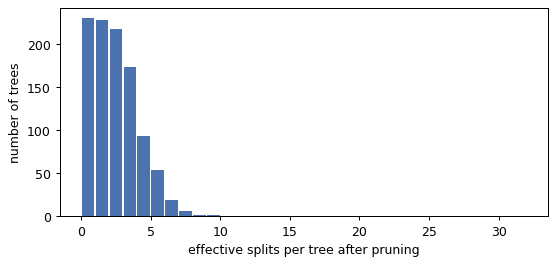

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(stats["effective_splits"], bins=range(0, stats["splits"].iloc[0] + 2), color="#4c72b0", rwidth=0.9)
ax.set_xlabel("effective splits per tree after pruning")
ax.set_ylabel("number of trees");

### 4.2 A single tree

`plot_tree` draws one tree of the ensemble by its index. Split nodes show the condition of the *yes* branch on
the original features (pass `feature_names`, otherwise the features are called `x_1, x_2, ...`). Leaves show
the predicted value and, in a separate line,
the leaf weight (the logit of the instance-wise estimator weight). With `X=...` every node shows how many samples
reach it, and `highlight=...` marks the decision path of one sample. A leaf value is the prediction of this tree alone; it can lie outside the range of the target, because the trees are trained jointly and compensate each other.

We look at the test person with the highest predicted charges, and plot the tree that receives the highest weight for it.

predicted charges: 46628, true: 47404, tree #633


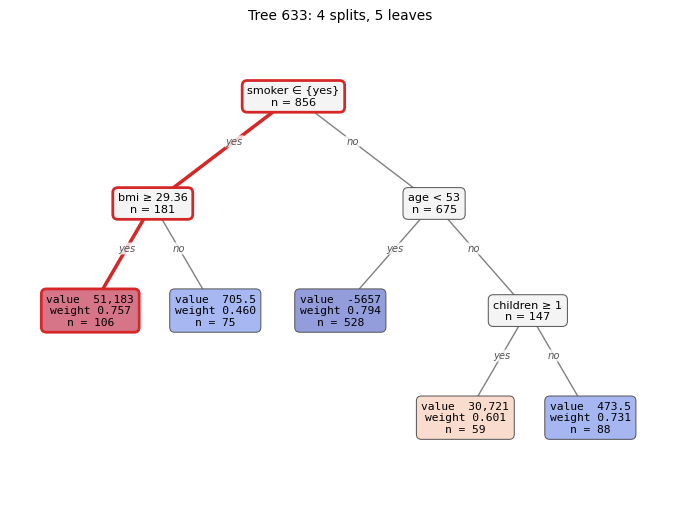

In [8]:
names = list(X.columns)
sample = X_test.iloc[[int(np.argmax(pred_grande))]]
explanation = model.explain_instance(sample)
tree_index = int(explanation["estimator"].iloc[0])  # the tree with the highest weight for this sample
print(f"predicted charges: {model.predict(sample)[0]:.0f}, true: {y_test.loc[sample.index[0]]:.0f}, tree #{tree_index}")
model.plot_tree(tree_index, feature_names=names, X=X_train, highlight=sample);

The same tree as text. `export_text` is handy in a terminal or a log file:

In [9]:
print(model.export_text(tree_index, feature_names=names))

Tree 633: 4 splits (31 before pruning), 5 leaves, depth 3
smoker ∈ {yes}
├─ yes: bmi ≥ 29.36
│  ├─ yes: leaf 3: value=51,183  | weight=0.757
│  └─ no:  leaf 9: value=705.5  | weight=0.460
└─ no:  age < 53
   ├─ yes: leaf 21: value=-5657  | weight=0.794
   └─ no:  children ≥ 1
      ├─ yes: leaf 22: value=30,721  | weight=0.601
      └─ no:  leaf 23: value=473.5  | weight=0.731


For comparison, the complete tree **before pruning** (`prune=False`). Redundant splits are dashed and annotated
with the branch they always take; branches that can never be reached are faded out.

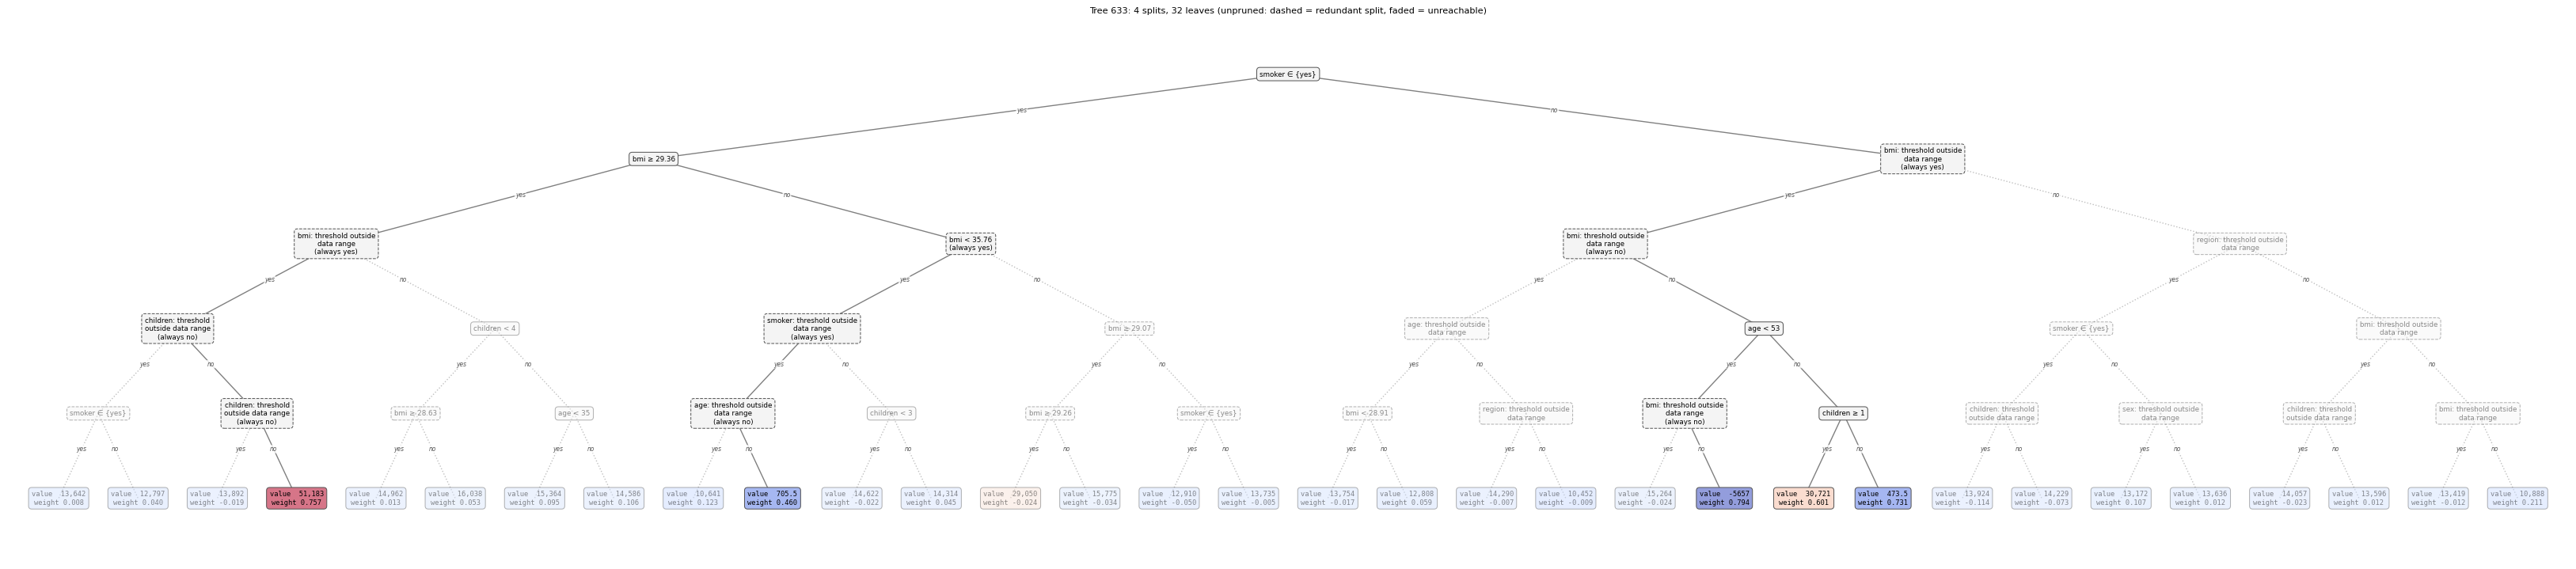

In [10]:
model.plot_tree(tree_index, prune=False, feature_names=names);

### 4.3 Feature importances

Two importance measures exploit the tree structure. Both only credit *effective* splits (see pruning) and
aggregate encodings and embedding dimensions to their original feature:

* **data-based** (`compute_feature_importances(X)`): for every sample and tree, the sample's estimator weight is
  shared among the effective splits on its decision path. A feature's importance is its share of all routing
  decisions of the ensemble on `X`.
* **structural** (`feature_importances_`, no data needed): every tree distributes its expected weight over its
  effective splits in proportion to the probability of reaching each split.

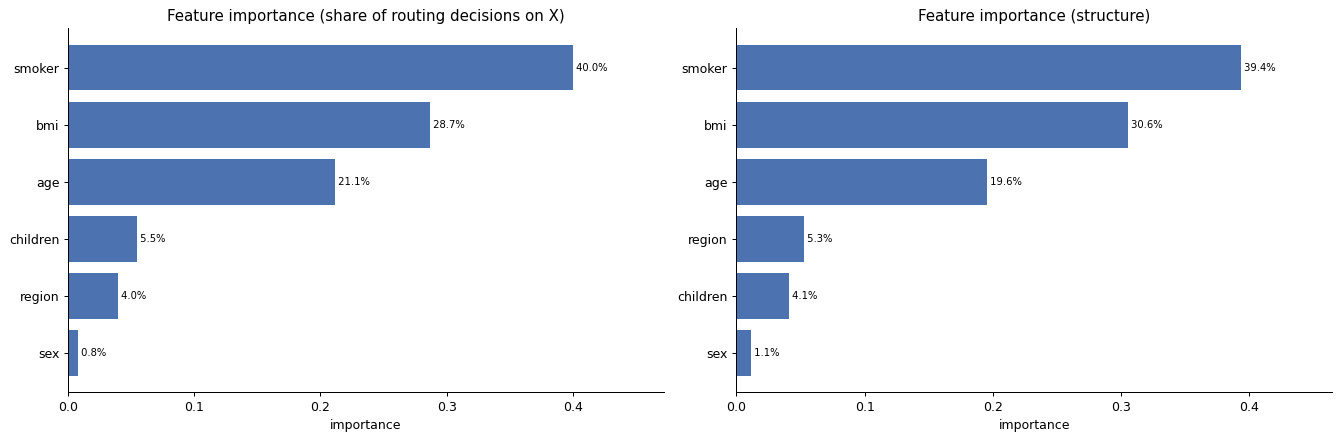

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
model.plot_feature_importances(X=X_test, feature_names=names, top_k=12, ax=axes[0])
model.plot_feature_importances(feature_names=names, top_k=12, ax=axes[1])
plt.tight_layout()

### 4.4 Explaining a single prediction

For one sample, `explain_instance` lists every tree with the leaf it reaches, its instance-wise **weight**
(softmax over all trees, sums to 1) and its **contribution** to the prediction
(in units of the target; prediction = mean + sum of contributions).

In [12]:
print({k: round(v, 4) if isinstance(v, float) else v for k, v in explanation.attrs.items()})
explanation.head(10).round(4)

{'effective_n_estimators': 781.9382, 'n_estimators': 1024, 'target': None, 'score': 32931.6952, 'prediction': 46627.7323, 'base': 13696.0371, 'prediction_label': 'prediction', 'contribution_unit': 'target units'}


,estimator,leaf,weight,weight_logit,leaf_prediction,contribution
0,633,3,0.0031,0.7566,51182.5763,116.1270
1,347,31,0.0028,0.6721,51450.7873,107.4830
2,965,7,0.0028,0.6482,49002.1560,98.1415
3,708,13,0.0028,0.6428,50761.1307,102.4693
4,137,30,0.0028,0.6412,50638.2078,101.9654
5,51,25,0.0027,0.6224,47945.7699,92.7805
6,366,2,0.0027,0.6113,49899.9616,96.9887
7,141,12,0.0027,0.6032,1124.7228,-33.4049
8,683,23,0.0026,0.5896,48756.7968,91.9091
9,622,26,0.0026,0.5880,48589.3748,91.3289


`plot_estimator_weights` shows how the weight is distributed over the trees for this sample (the effective
number of trees is 1 / sum of squared weights), which trees receive the most weight and how much they
contribute:

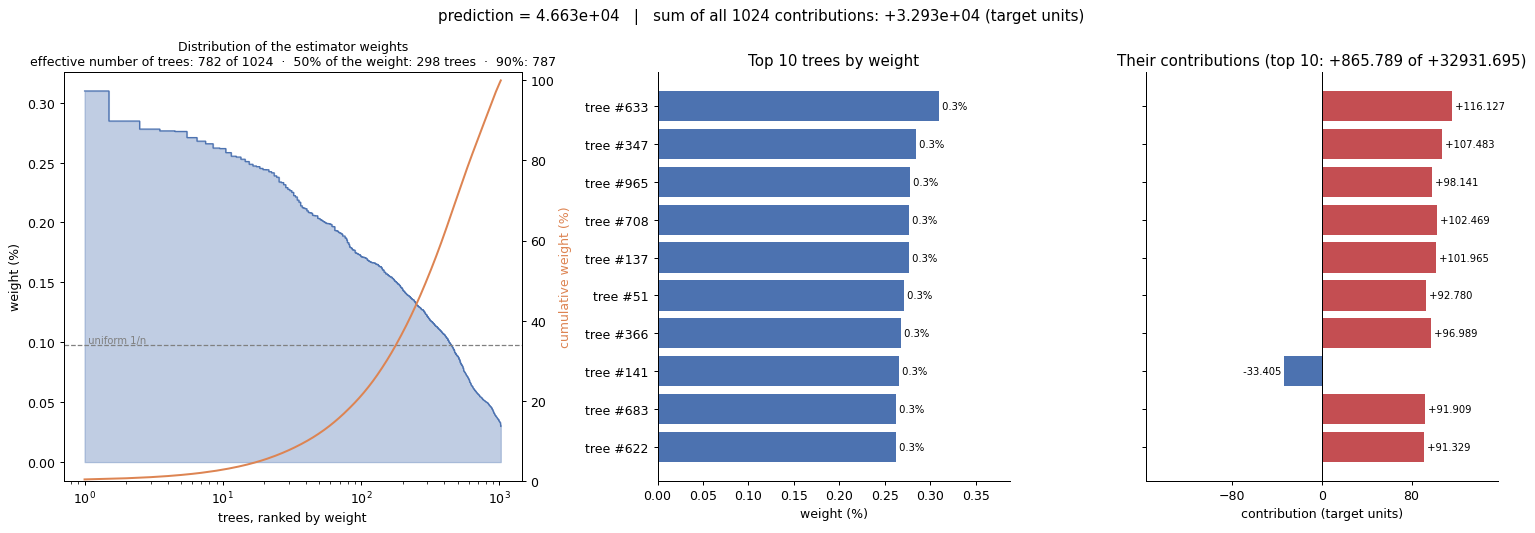

In [13]:
model.plot_estimator_weights(sample, top_k=10);

`plot_top_estimators` draws the trees with the highest weight for this sample side by side, with the decision
path of the sample highlighted:

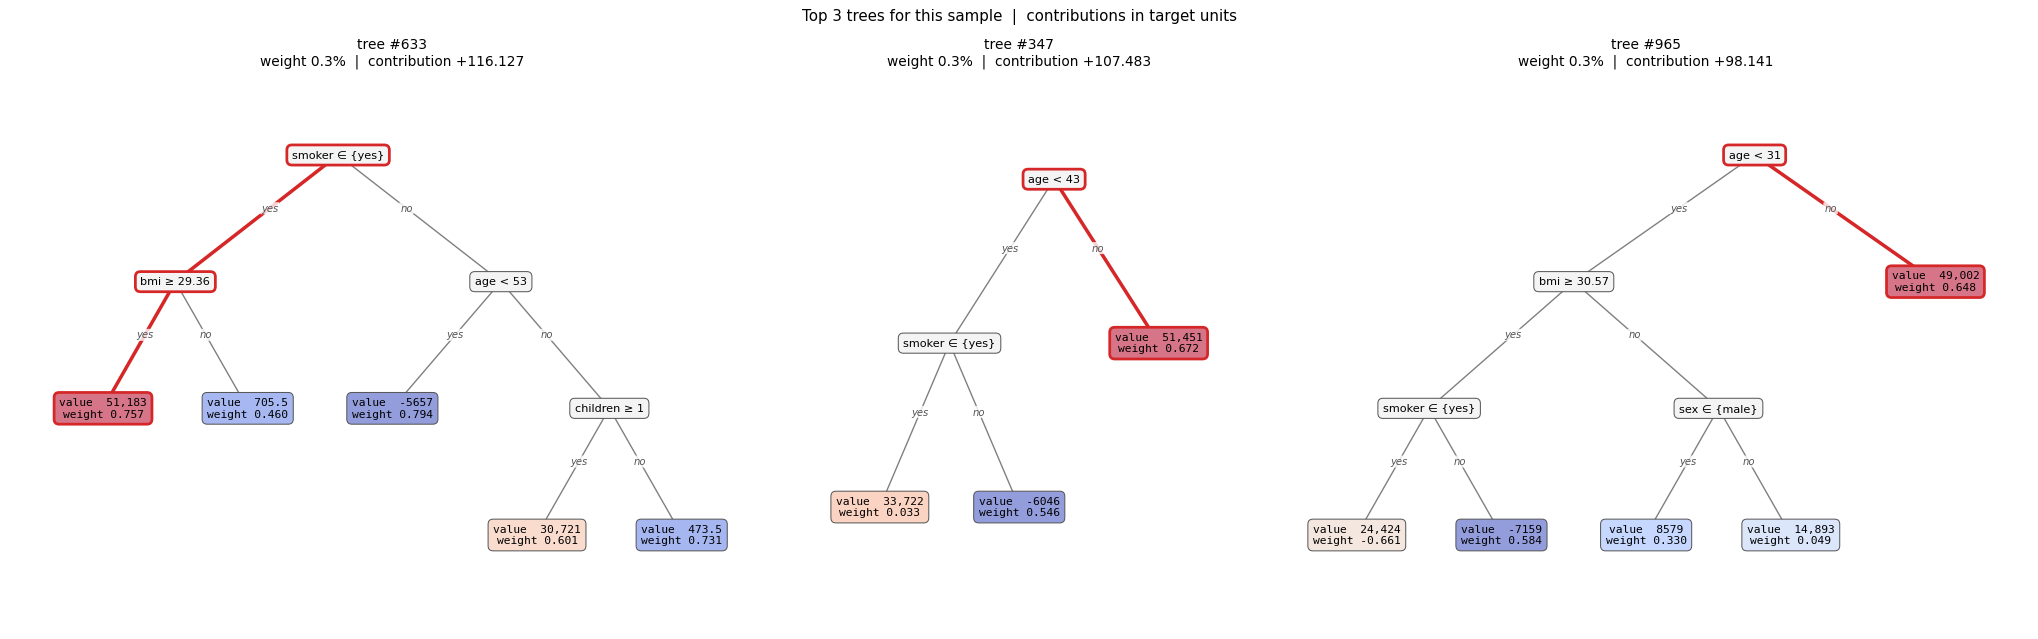

In [14]:
model.plot_top_estimators(sample, k=3, feature_names=names);

### 4.5 Which features drive this prediction?

The view above attributes the prediction to *trees*. `explain_features` attributes it to the *input features*
with Shapley values: each feature receives its average contribution over all orders in which features can be
switched from a reference sample to the explained sample. The references are a background sample of the
training data; the attributions add up to the prediction minus the mean prediction over the background
(in units of the target).

GRANDE weights its trees per sample, so the output is not a plain sum over trees and the usual TreeSHAP
shortcut does not apply. Instead, features that do not change any split for a background row are dropped
(they contribute exactly 0) and the remaining ones are enumerated exactly if there are at most 12 of them,
or sampled otherwise.

In [15]:
background = X_train.sample(100, random_state=0)
attributions = model.explain_features(sample, background, feature_names=names)
print({k: round(v, 4) if isinstance(v, float) else v for k, v in attributions.attrs.items()})
attributions.head(8).round(4)

{'base_value': 14273.8634, 'score': 46627.7323, 'n_references': 100, 'n_exact': 100, 'n_sampled': 0, 'n_dummy_references': 0, 'unit': 'target units', 'prediction': 46627.7323, 'prediction_label': 'prediction', 'target': None}


,feature,value,attribution
0,smoker,yes,20767.6670
1,bmi,36.3,6158.6606
2,age,61,5574.3096
3,region,southwest,-228.6606
4,children,1,129.2308
5,sex,male,-47.3385


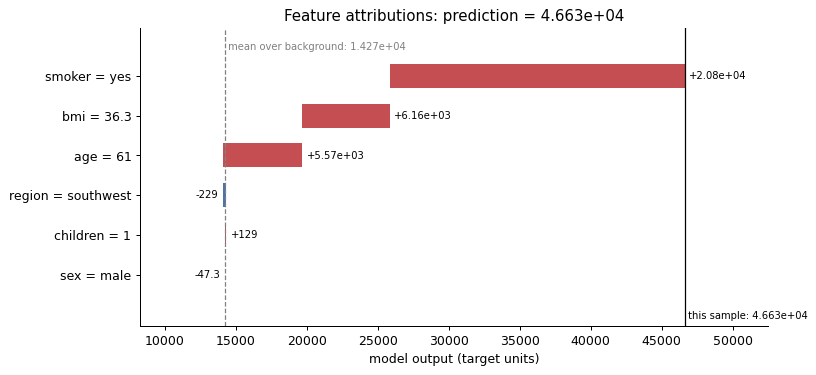

In [16]:
model.plot_feature_attributions(attributions=attributions, top_k=8);

### 4.6 Rules

Every leaf of a pruned tree is a readable rule: the conditions on its path. `extract_rules` ranks the leaves by
how much the ensemble relies on them (`weight_share`: the instance-wise estimator weight on the leaf, summed
over the covered samples) times how strongly they change the prediction (`lift`: mean prediction on the covered samples minus the overall mean).
Broad rules that hold for nearly everybody therefore rank low. Leaves of different trees that cover almost
the same samples are merged (`n_trees`). The rules are extracted on the training data:

In [17]:
rules = model.extract_rules(X_train, y_train, top_k=10, feature_names=names)
print("mean prediction on the training data:", round(rules.attrs['base']))
rules.drop(columns=["tree", "leaf", "impact"]).round(3).round({"mean_prediction": 0, "mean_target": 0, "lift": 0})

mean prediction on the training data: 13703


,rule,mean_prediction,mean_target,lift,coverage,weight_share,n_trees
0,bmi ≥ 20.37 AND smoker = yes,33604.0,33698.0,19900.0,0.202,0.047,235
1,smoker = no,8551.0,8507.0,-5153.0,0.789,0.135,146
2,age < 52 AND smoker = no,6902.0,6809.0,-6801.0,0.603,0.043,47
3,bmi ≥ 30.22 AND smoker = no,8989.0,8887.0,-4715.0,0.401,0.051,82
4,bmi < 30.28,10928.0,10925.0,-2775.0,0.486,0.051,63
5,bmi ≥ 29.36 AND smoker = yes,41186.0,41384.0,27482.0,0.124,0.005,27
6,age < 58 AND smoker = no,7691.0,7623.0,-6012.0,0.690,0.019,19
7,age < 48 AND smoker = no,6388.0,6360.0,-7316.0,0.532,0.015,21
8,children < 3 AND smoker = no,8339.0,8402.0,-5364.0,0.674,0.020,23
9,age < 44 AND smoker = no,5816.0,5756.0,-7887.0,0.454,0.012,20


Do the rules hold on new data? We check the coverage and the mean charges of the same rules on the test data:

In [18]:
test_leaves = model.apply(X_test)
checks = []
for _, rule in rules.iterrows():
    covered = test_leaves[:, rule["tree"]] == rule["leaf"]
    checks.append({"rule": rule["rule"], "test coverage": covered.mean(),
                   "mean charges (test, covered)": y_test.to_numpy()[covered].mean(),
                   "mean charges (test, all)": y_test.mean()})
pd.DataFrame(checks).round(3).round({"mean charges (test, covered)": 0, "mean charges (test, all)": 0})

,rule,test coverage,"mean charges (test, covered)","mean charges (test, all)"
0,bmi ≥ 20.37 AND smoker = yes,0.175,28879.0,11782.0
1,smoker = no,0.813,8013.0,11782.0
2,age < 52 AND smoker = no,0.575,6105.0,11782.0
3,bmi ≥ 30.22 AND smoker = no,0.396,8151.0,11782.0
4,bmi < 30.28,0.537,10903.0,11782.0
5,bmi ≥ 29.36 AND smoker = yes,0.075,39103.0,11782.0
6,age < 58 AND smoker = no,0.713,7189.0,11782.0
7,age < 48 AND smoker = no,0.507,5307.0,11782.0
8,children < 3 AND smoker = no,0.709,7762.0,11782.0
9,age < 44 AND smoker = no,0.455,4966.0,11782.0


## 5. Saving and loading

Fitted estimators can be pickled, or saved with `save` and loaded with `load`. `load(path, device="cpu")` moves
a model trained on a GPU to the CPU (predictions then differ slightly, as GPUs compute matrix products with
reduced precision, TF32).

In [19]:
import os

model.save("grande_insurance.pt")
restored = GRANDERegressor.load("grande_insurance.pt")
print(f"restored on {restored.device_}, identical predictions: {np.array_equal(restored.predict(X_test), model.predict(X_test))}")
os.remove("grande_insurance.pt")

restored on cuda:0, identical predictions: True
